In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
sns.set_style("darkgrid")
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from sklearn.metrics import (
    f1_score, roc_auc_score, accuracy_score,
    precision_score, recall_score, confusion_matrix,
    classification_report
)

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    print("XGBoost not found. Install with: pip install xgboost")
    HAS_XGB = False

try:
    from lightgbm import LGBMClassifier
    HAS_LGB = True
except ImportError:
    print("LightGBM not found. Install with: pip install lightgbm")
    HAS_LGB = False

try:
    from imblearn.over_sampling import SMOTE
    HAS_SMOTE = True
except ImportError:
    print("imbalanced-learn not found. Install with: pip install imbalanced-learn")
    HAS_SMOTE = False

SEED = 42
np.random.seed(SEED)
COLOR_POS  = '#E74C3C'   # heart disease
COLOR_NEG  = '#2E86AB'   # no disease
PALETTE    = [COLOR_NEG, COLOR_POS]

In [68]:
df = pd.read_csv("heart_2020_cleaned.csv")
df = df.drop_duplicates()
df

,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,Sex,AgeCategory,Race,Diabetic,PhysicalActivity,GenHealth,SleepTime,Asthma,KidneyDisease,SkinCancer
0,No,16.60,Yes,No,No,3.0,30.0,No,Female,55-59,White,Yes,Yes,Very good,5.0,Yes,No,Yes
1,No,20.34,No,No,Yes,0.0,0.0,No,Female,80 or older,White,No,Yes,Very good,7.0,No,No,No
2,No,26.58,Yes,No,No,20.0,30.0,No,Male,65-69,White,Yes,Yes,Fair,8.0,Yes,No,No
3,No,24.21,No,No,No,0.0,0.0,No,Female,75-79,White,No,No,Good,6.0,No,No,Yes
4,No,23.71,No,No,No,28.0,0.0,Yes,Female,40-44,White,No,Yes,Very good,8.0,No,No,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
319790,Yes,27.41,Yes,No,No,7.0,0.0,Yes,Male,60-64,Hispanic,Yes,No,Fair,6.0,Yes,No,No
319791,No,29.84,Yes,No,No,0.0,0.0,No,Male,35-39,Hispanic,No,Yes,Very good,5.0,Yes,No,No
319792,No,24.24,No,No,No,0.0,0.0,No,Female,45-49,Hispanic,No,Yes,Good,6.0,No,No,No
319793,No,32.81,No,No,No,0.0,0.0,No,Female,25-29,Hispanic,No,No,Good,12.0,No,No,No


#EDA

In [69]:
!pip install ydata-profiling
from ydata_profiling import ProfileReport
profile = ProfileReport(
    df,
    title="EDA DATA",
    explorative=True
)
profile.to_file("Heart Deasis Prediction.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 18/18 [00:06<00:00,  2.79it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [26]:
df.shape

(301717, 18)

In [27]:
binary_cols = ["Smoking", "AlcoholDrinking", "Stroke", "DiffWalking",
               "PhysicalActivity", "Asthma", "KidneyDisease", "SkinCancer"]

for c in binary_cols:
    df[c] = (df[c] == "Yes").astype(int)

In [28]:
df.head()

,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,Sex,AgeCategory,Race,Diabetic,PhysicalActivity,GenHealth,SleepTime,Asthma,KidneyDisease,SkinCancer
0,No,16.60,1,0,0,3.0,30.0,0,Female,55-59,White,Yes,1,Very good,5.0,1,0,1
1,No,20.34,0,0,1,0.0,0.0,0,Female,80 or older,White,No,1,Very good,7.0,0,0,0
2,No,26.58,1,0,0,20.0,30.0,0,Male,65-69,White,Yes,1,Fair,8.0,1,0,0
3,No,24.21,0,0,0,0.0,0.0,0,Female,75-79,White,No,0,Good,6.0,0,0,1
4,No,23.71,0,0,0,28.0,0.0,1,Female,40-44,White,No,1,Very good,8.0,0,0,0


In [29]:
num_cols = ['BMI', 'PhysicalHealth', 'MentalHealth', 'SleepTime']
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
BMI,301717.0,28.44,6.47,12.02,24.03,27.41,31.65,94.85
PhysicalHealth,301717.0,3.57,8.14,0.00,0.00,0.00,2.00,30.00
MentalHealth,301717.0,4.12,8.13,0.00,0.00,0.00,4.00,30.00
SleepTime,301717.0,7.08,1.47,1.00,6.00,7.00,8.00,24.00


In [30]:
summary = pd.DataFrame({
    'dtype'   : df.dtypes,
    'nulls'   : df.isnull().sum(),
    'null_%'  : (df.isnull().mean() * 100).round(2),
    'nunique' : df.nunique(),
    'sample'  : [df[c].dropna().unique()[:3] for c in df.columns]
})
summary

,dtype,nulls,null_%,nunique,sample
HeartDisease,object,0,0.0,2,"[No, Yes]"
BMI,float64,0,0.0,3604,"[16.6, 20.34, 26.58]"
Smoking,int64,0,0.0,2,"[1, 0]"
AlcoholDrinking,int64,0,0.0,2,"[0, 1]"
Stroke,int64,0,0.0,2,"[0, 1]"
PhysicalHealth,float64,0,0.0,31,"[3.0, 0.0, 20.0]"
MentalHealth,float64,0,0.0,31,"[30.0, 0.0, 2.0]"
DiffWalking,int64,0,0.0,2,"[0, 1]"
Sex,object,0,0.0,2,"[Female, Male]"
AgeCategory,object,0,0.0,13,"[55-59, 80 or older, 65-69]"


التوزيع:
No: 274,456 (91.0%)
Yes: 27,261 (9.0%)


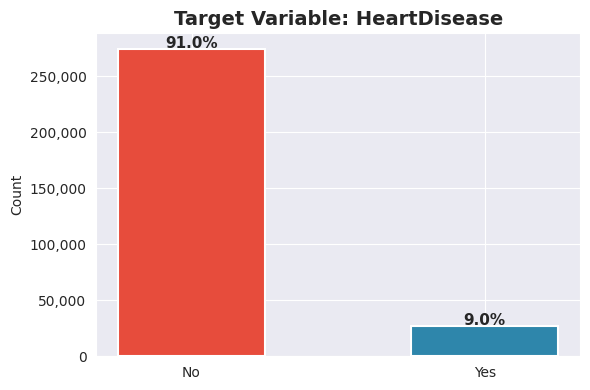


⚠️ الداتا imbalanced — نسبة 1:10 تقريباً


In [31]:
target_counts = df['HeartDisease'].value_counts()
target_pct = df['HeartDisease'].value_counts(normalize=True) * 100

print('التوزيع:')
for label in target_counts.index:
    print(f'{label}: {target_counts[label]:,} ({target_pct[label]:.1f}%)')

plt.figure(figsize=(6,4))

bars = plt.bar(
    target_counts.index,
    target_counts.values,
    color=PALETTE[::-1],
    edgecolor='white',
    linewidth=1.5,
    width=0.5
)
for bar, pct in zip(bars, target_pct.values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1000,
        f'{pct:.1f}%',
        ha='center',
        fontsize=11,
        fontweight='bold'
    )

plt.title('Target Variable: HeartDisease', fontsize=14, fontweight='bold')
plt.ylabel('Count')

plt.gca().yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{x:,.0f}')
)

plt.tight_layout()
plt.show()

print(f'\n⚠️ الداتا imbalanced — نسبة 1:{target_pct["No"]/target_pct["Yes"]:.0f} تقريباً')

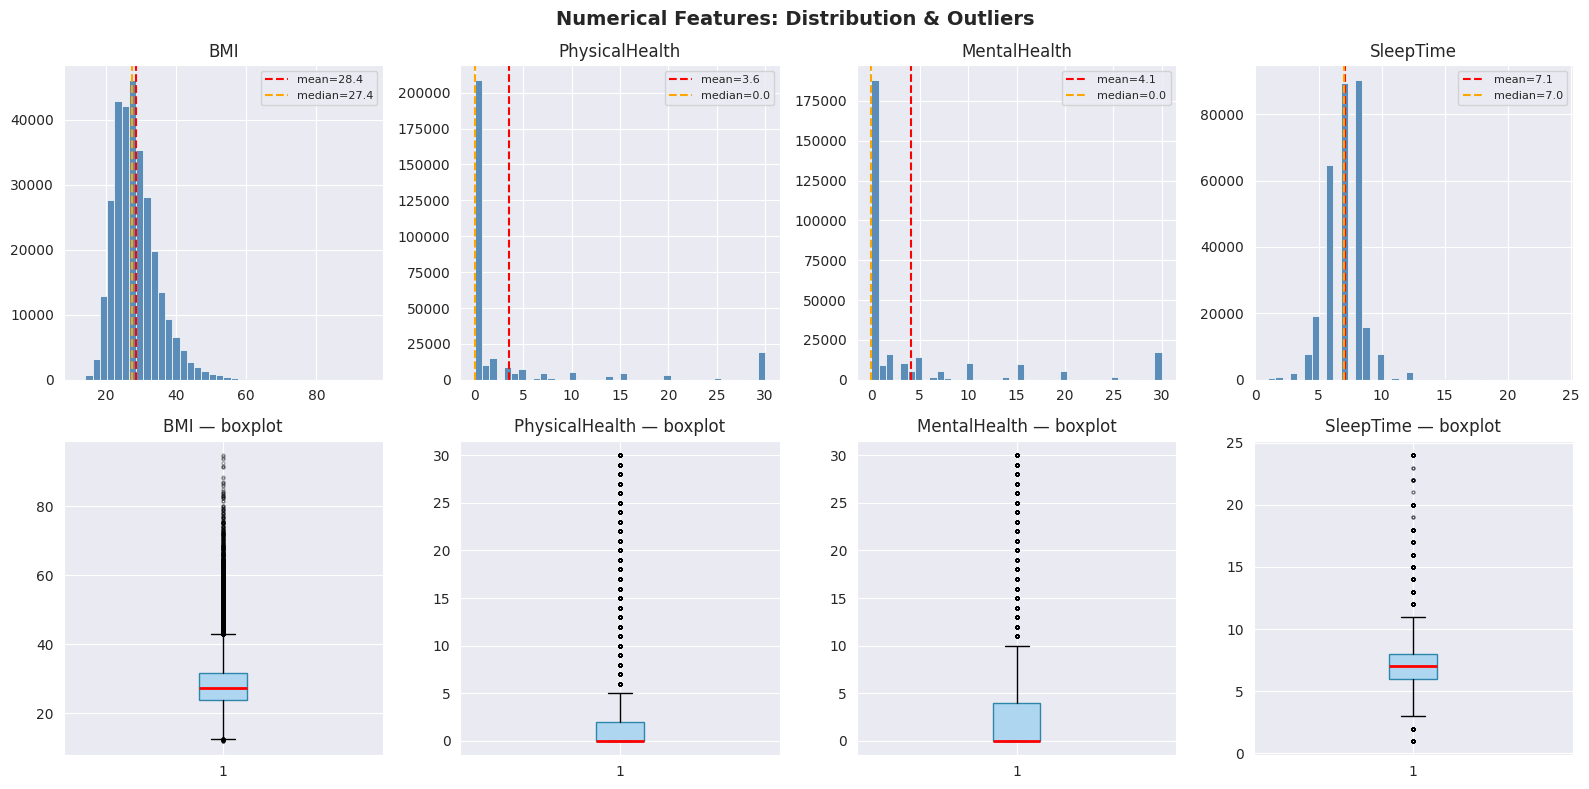

In [32]:
num_cols = ['BMI', 'PhysicalHealth', 'MentalHealth', 'SleepTime']
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, col in enumerate(num_cols):
    ax_hist = axes[0, i]
    ax_hist.hist(df[col].dropna(), bins=40, color='#5B8DB8', edgecolor='white', linewidth=0.5)
    ax_hist.axvline(df[col].mean(),   color='red',    linestyle='--', linewidth=1.5, label=f'mean={df[col].mean():.1f}')
    ax_hist.axvline(df[col].median(), color='orange', linestyle='--', linewidth=1.5, label=f'median={df[col].median():.1f}')
    ax_hist.set_title(col)
    ax_hist.legend(fontsize=8)
    ax_box = axes[1, i]
    ax_box.boxplot(df[col].dropna(), vert=True, patch_artist=True,
                   boxprops=dict(facecolor='#AED6F1', color='#2E86AB'),
                   medianprops=dict(color='red', linewidth=2),
                   flierprops=dict(marker='o', markersize=2, alpha=0.3))
    ax_box.set_title(f'{col} — boxplot')
fig.suptitle('Numerical Features: Distribution & Outliers', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

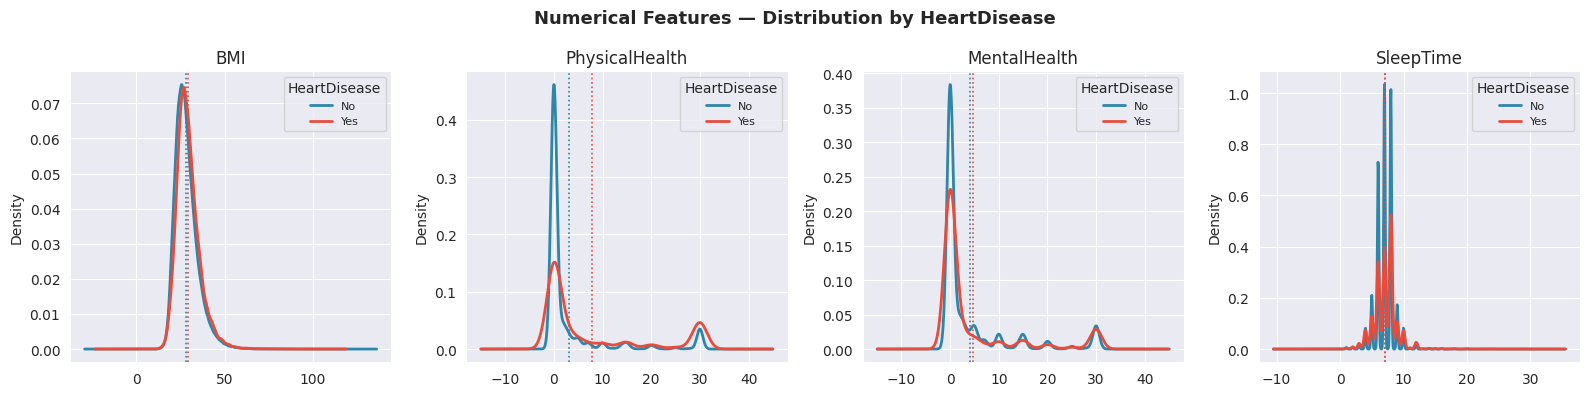

In [33]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, col in zip(axes, num_cols):
    for label, color in zip(['No', 'Yes'], PALETTE):
        subset = df[df['HeartDisease'] == label][col].dropna()
        subset.plot.kde(ax=ax, color=color, linewidth=2, label=label)
        ax.axvline(subset.mean(), color=color, linestyle=':', linewidth=1.2)
    ax.set_title(col)
    ax.set_xlabel('')
    ax.legend(title='HeartDisease', fontsize=8)

fig.suptitle('Numerical Features — Distribution by HeartDisease', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

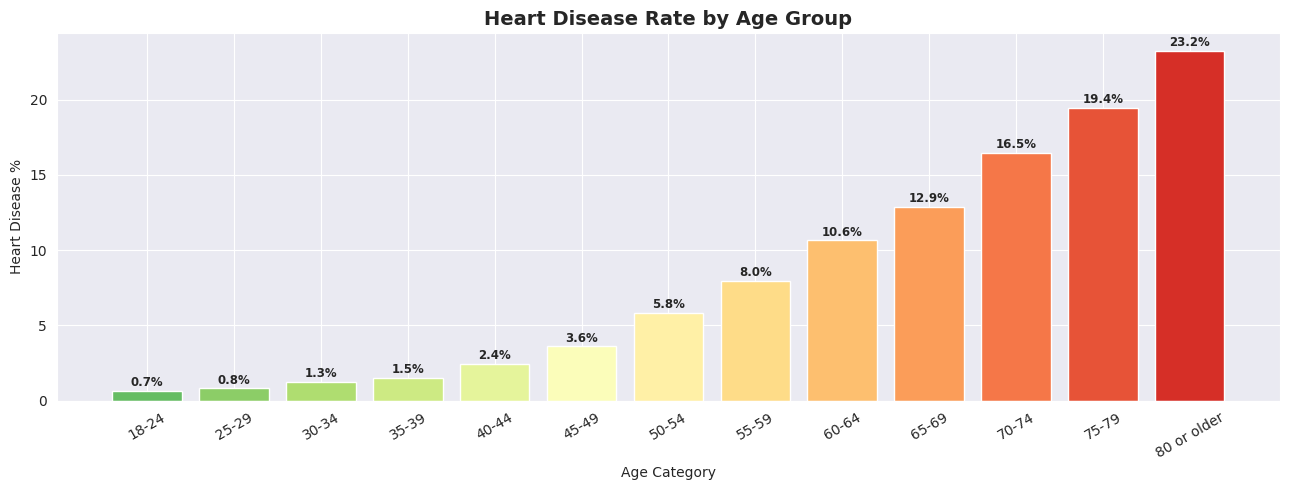

In [34]:
age_rate = df.groupby('AgeCategory')['HeartDisease'].apply(
    lambda x: (x == 'Yes').mean() * 100
).reset_index()
age_rate.columns = ['AgeCategory', 'heart_disease_rate']

# ترتيب منطقي
age_order = ['18-24','25-29','30-34','35-39','40-44','45-49',
             '50-54','55-59','60-64','65-69','70-74','75-79','80 or older']
age_rate['AgeCategory'] = pd.Categorical(age_rate['AgeCategory'], categories=age_order, ordered=True)
age_rate = age_rate.sort_values('AgeCategory')

fig, ax = plt.subplots(figsize=(13, 5))
colors = plt.cm.RdYlGn_r(np.linspace(0.2, 0.9, len(age_rate)))
bars = ax.bar(age_rate['AgeCategory'].astype(str), age_rate['heart_disease_rate'],
              color=colors, edgecolor='white', linewidth=1)
for bar, val in zip(bars, age_rate['heart_disease_rate']):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.3,
            f'{val:.1f}%', ha='center', fontsize=8.5, fontweight='bold')

ax.set_title('Heart Disease Rate by Age Group', fontsize=14, fontweight='bold')
ax.set_xlabel('Age Category')
ax.set_ylabel('Heart Disease %')
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

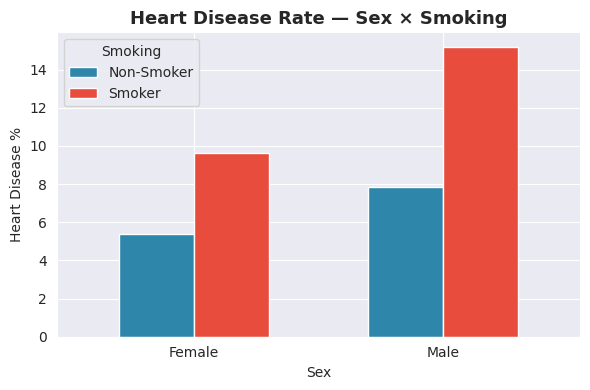

In [35]:
pivot2 = df.groupby(['Sex', 'Smoking'])['HeartDisease'].apply(
    lambda x: (x == 'Yes').mean() * 100
).unstack()

fig, ax = plt.subplots(figsize=(6, 4))
pivot2.plot(kind='bar', ax=ax, color=[COLOR_NEG, COLOR_POS], edgecolor='white', width=0.6)
ax.set_title('Heart Disease Rate — Sex × Smoking', fontsize=13, fontweight='bold')
ax.set_ylabel('Heart Disease %')
ax.set_xlabel('Sex')
ax.legend(title='Smoking', labels=['Non-Smoker', 'Smoker'])
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

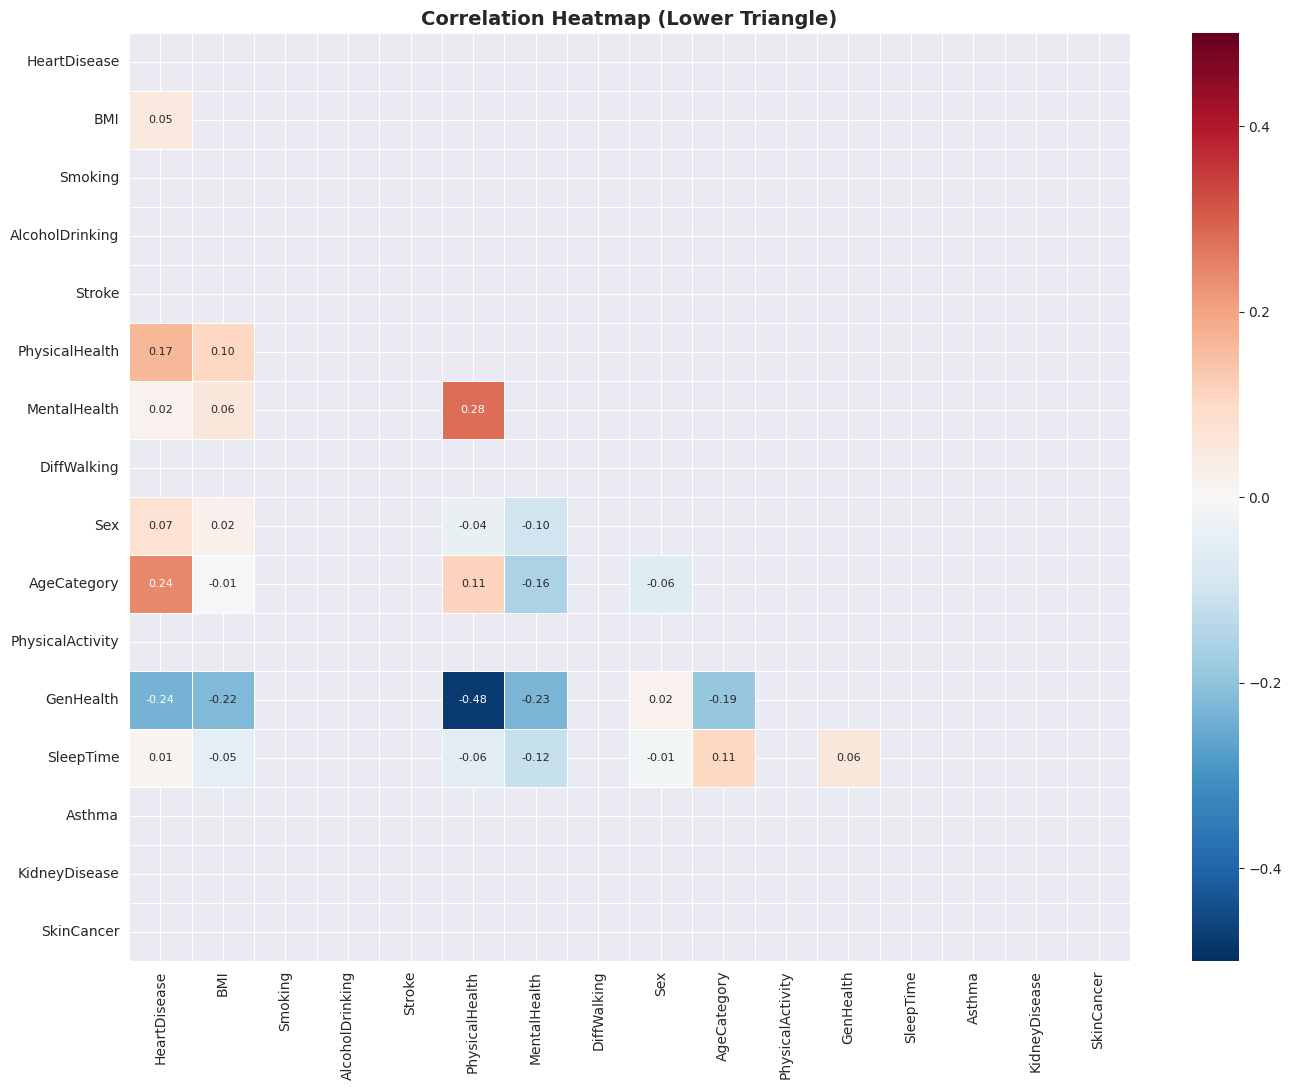

In [36]:
df_enc = df.copy()

df_enc['HeartDisease'] = (df_enc['HeartDisease'] == 'Yes').astype(int)
df_enc['Sex']          = (df_enc['Sex'] == 'Male').astype(int)

binary_cols = ['Smoking','AlcoholDrinking','Stroke','DiffWalking',
               'PhysicalActivity','Asthma','KidneyDisease','SkinCancer']
for c in binary_cols:
    df_enc[c] = (df_enc[c] == 'Yes').astype(int)

age_order = ['18-24','25-29','30-34','35-39','40-44','45-49',
             '50-54','55-59','60-64','65-69','70-74','75-79','80 or older']
df_enc['AgeCategory'] = pd.Categorical(df_enc['AgeCategory'], categories=age_order, ordered=True).codes

gh_order = ['Poor','Fair','Good','Very good','Excellent']
df_enc['GenHealth'] = pd.Categorical(df_enc['GenHealth'], categories=gh_order, ordered=True).codes

df_enc = df_enc.select_dtypes(include=np.number)

corr_matrix = df_enc.corr()

fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix,
            mask=mask,
            annot=True,
            fmt='.2f',
            cmap='RdBu_r',
            center=0,
            vmin=-0.5, vmax=0.5,
            linewidths=0.5,
            ax=ax,
            annot_kws={'size': 8})
ax.set_title('Correlation Heatmap (Lower Triangle)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [37]:
print('=' * 60)
print('EDA SUMMARY — KEY FINDINGS')
print('=' * 60)

print(f'''
  Dataset
  - {len(df):,} records × {df.shape[1]} features
  - No missing values
  - Duplicates removed

  Class Imbalance
  - HeartDisease = Yes : ~9%
  - HeartDisease = No  : ~91%
  - محتاج SMOTE أو class_weight لازم قبل أي موديل

  Strongest Risk Factors (من الـ correlation)
  1. AgeCategory   — كلما كبر السن، زادت النسبة بشكل واضح
  2. GenHealth     — الناس اللي حالتها الصحية Poor عندها أعلى نسبة
  3. DiffWalking   — صعوبة المشي مرتبطة بالـ heart disease
  4. Stroke        — اللي عندهم stroke تاريخ أعلى نسبة بكتير
  5. PhysicalHealth— كتير من أيام مرضية physical = risk أعلى

  Interesting Patterns
  - BMI Obese III عنده أعلى heart disease rate في الـ BMI categories
  - السن 80+ عنده أعلى نسبة heart disease (>30%)
  - GenHealth=Poor عنده نسبة أعلى بكتير من Excellent
  - الـ AlcoholDrinking عنده correlation سلبية (غريبة — ممكن reporting bias)
  - الـ KidneyDisease و SkinCancer عندهم correlation معقولة بالرغم من ندرتهم

  - Ordinal encoding لـ AgeCategory و GenHealth (ترتيب منطقي)
  - One-hot لـ Race و Diabetic
  - Binary encoding لـ Yes/No columns
  - Scaling لـ BMI, PhysicalHealth, MentalHealth, SleepTime
  - SMOTE على الـ training set بس
''')

EDA SUMMARY — KEY FINDINGS

  Dataset
  - 301,717 records × 18 features
  - No missing values
  - Duplicates removed

  Class Imbalance
  - HeartDisease = Yes : ~9%
  - HeartDisease = No  : ~91%
  - محتاج SMOTE أو class_weight لازم قبل أي موديل

  Strongest Risk Factors (من الـ correlation)
  1. AgeCategory   — كلما كبر السن، زادت النسبة بشكل واضح
  2. GenHealth     — الناس اللي حالتها الصحية Poor عندها أعلى نسبة
  3. DiffWalking   — صعوبة المشي مرتبطة بالـ heart disease
  4. Stroke        — اللي عندهم stroke تاريخ أعلى نسبة بكتير
  5. PhysicalHealth— كتير من أيام مرضية physical = risk أعلى

  Interesting Patterns
  - BMI Obese III عنده أعلى heart disease rate في الـ BMI categories
  - السن 80+ عنده أعلى نسبة heart disease (>30%)
  - GenHealth=Poor عنده نسبة أعلى بكتير من Excellent
  - الـ AlcoholDrinking عنده correlation سلبية (غريبة — ممكن reporting bias)
  - الـ KidneyDisease و SkinCancer عندهم correlation معقولة بالرغم من ندرتهم

  - Ordinal encoding لـ AgeCategory و GenHealth (ترت

#Preprocessing

In [38]:
df["Sex"] = (df["Sex"] == "Male").astype(int)

In [39]:
age_order = ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49",
             "50-54", "55-59", "60-64", "65-69", "70-74", "75-79", "80 or older"]
df["AgeCategory"] = pd.Categorical(df["AgeCategory"], categories=age_order, ordered=True)
df["AgeCategory"] = df["AgeCategory"].cat.codes

In [40]:
gh_order = ["Poor", "Fair", "Good", "Very good", "Excellent"]
df["GenHealth"] = pd.Categorical(df["GenHealth"], categories=gh_order, ordered=True)
df["GenHealth"] = df["GenHealth"].cat.codes

In [41]:
df = pd.get_dummies(df, columns=["Race", "Diabetic"], drop_first=True)
df["HeartDisease"] = (df["HeartDisease"] == "Yes").astype(int)

In [42]:
df.head()

,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,Sex,AgeCategory,...,KidneyDisease,SkinCancer,Race_Asian,Race_Black,Race_Hispanic,Race_Other,Race_White,"Diabetic_No, borderline diabetes",Diabetic_Yes,Diabetic_Yes (during pregnancy)
0,0,16.60,1,0,0,3.0,30.0,0,0,7,...,0,1,False,False,False,False,True,False,True,False
1,0,20.34,0,0,1,0.0,0.0,0,0,12,...,0,0,False,False,False,False,True,False,False,False
2,0,26.58,1,0,0,20.0,30.0,0,1,9,...,0,0,False,False,False,False,True,False,True,False
3,0,24.21,0,0,0,0.0,0.0,0,0,11,...,0,1,False,False,False,False,True,False,False,False
4,0,23.71,0,0,0,28.0,0.0,1,0,4,...,0,0,False,False,False,False,True,False,False,False


In [43]:
X = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]

print(f"Dataset shape: {df.shape}")
print(f"Positive class %: {y.mean()*100:.2f}%")
print(f"Class distribution: {y.value_counts().to_dict()}")

Dataset shape: (301717, 24)
Positive class %: 9.04%
Class distribution: {0: 274456, 1: 27261}


In [44]:
def engineer(df):
    df = df.copy()
    # Interaction features
    df["Age_BMI"]      = df["AgeCategory"] * df["BMI"]
    df["BMI_sq"]       = df["BMI"] ** 2
    df["BMI_Obese"]    = (df["BMI"] >= 30).astype(int)
    df["Smoking_Age"]  = df["Smoking"] * df["AgeCategory"]
    # Risk flags
    df["HighRisk"]     = ((df["Stroke"] == 1) | (df["DiffWalking"] == 1)).astype(int)
    df["SleepRisk"]    = ((df["SleepTime"] < 6) | (df["SleepTime"] > 9)).astype(int)
    df["Comorbid"]     = df["Stroke"] + df["Asthma"] + df["KidneyDisease"] + df["SkinCancer"]
    df["Age_Comorbid"] = df["AgeCategory"] * df["Comorbid"]
    # Mental/Physical health interaction
    df["Health_Score"] = df["GenHealth"] - (df["PhysicalHealth"] + df["MentalHealth"]) / 30
    # Lifestyle score
    df["Lifestyle_Bad"] = (
        (df["Smoking"] == 1).astype(int) +
        (df["AlcoholDrinking"] == 1).astype(int) +
        (df["PhysicalActivity"] == 0).astype(int) +
        df["SleepRisk"]
    )
    return df

df= engineer(X)
print(f"\nFeatures after engineering: {X.shape[1]}")


Features after engineering: 23


In [45]:
df.head()

,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,Sex,AgeCategory,PhysicalActivity,...,Age_BMI,BMI_sq,BMI_Obese,Smoking_Age,HighRisk,SleepRisk,Comorbid,Age_Comorbid,Health_Score,Lifestyle_Bad
0,16.60,1,0,0,3.0,30.0,0,0,7,1,...,116.20,275.5600,0,7,0,1,2,14,1.900000,2
1,20.34,0,0,1,0.0,0.0,0,0,12,1,...,244.08,413.7156,0,0,1,0,1,12,3.000000,0
2,26.58,1,0,0,20.0,30.0,0,1,9,1,...,239.22,706.4964,0,9,0,0,1,9,-0.666667,1
3,24.21,0,0,0,0.0,0.0,0,0,11,0,...,266.31,586.1241,0,0,0,0,1,11,2.000000,1
4,23.71,0,0,0,28.0,0.0,1,0,4,1,...,94.84,562.1641,0,0,1,0,0,0,2.066667,0


In [46]:
X_train, X_test, y_train, y_test = train_test_split(
    X.values, y.values,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print(f"\nTrain: {X_train.shape}  |  Test: {X_test.shape}")
print(f"Train positive %: {y_train.mean()*100:.2f}%")


Train: (241373, 23)  |  Test: (60344, 23)
Train positive %: 9.04%


#Feature Selection

In [47]:
mi_scores = mutual_info_classif(X_train, y_train, random_state=42)
mi_series = pd.Series(mi_scores, index=X.columns).sort_values(ascending=False)

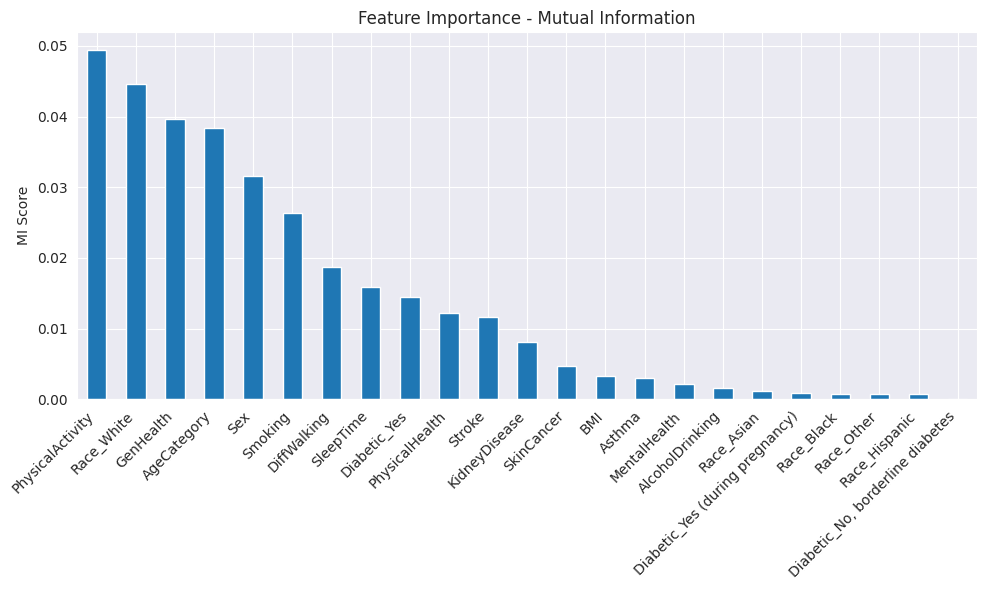

In [48]:
plt.figure(figsize=(10, 6))
mi_series.plot(kind='bar')
plt.title('Feature Importance - Mutual Information')
plt.ylabel('MI Score')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [49]:
rf = RandomForestClassifier(n_estimators=100, class_weight="balanced" , random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=42)


=== Random Forest Feature Importances ===
BMI                                 0.263428
AgeCategory                         0.192474
GenHealth                           0.094606
SleepTime                           0.087634
PhysicalHealth                      0.063556
MentalHealth                        0.055644
DiffWalking                         0.031783
Diabetic_Yes                        0.029304
Sex                                 0.025732
Stroke                              0.025411
Smoking                             0.020300
PhysicalActivity                    0.019227
Asthma                              0.016346
SkinCancer                          0.013656
KidneyDisease                       0.013256
Race_White                          0.011659
AlcoholDrinking                     0.009024
Race_Hispanic                       0.006325
Race_Black                          0.006227
Diabetic_No, borderline diabetes    0.005794
Race_Other                          0.004419
Race_Asian  

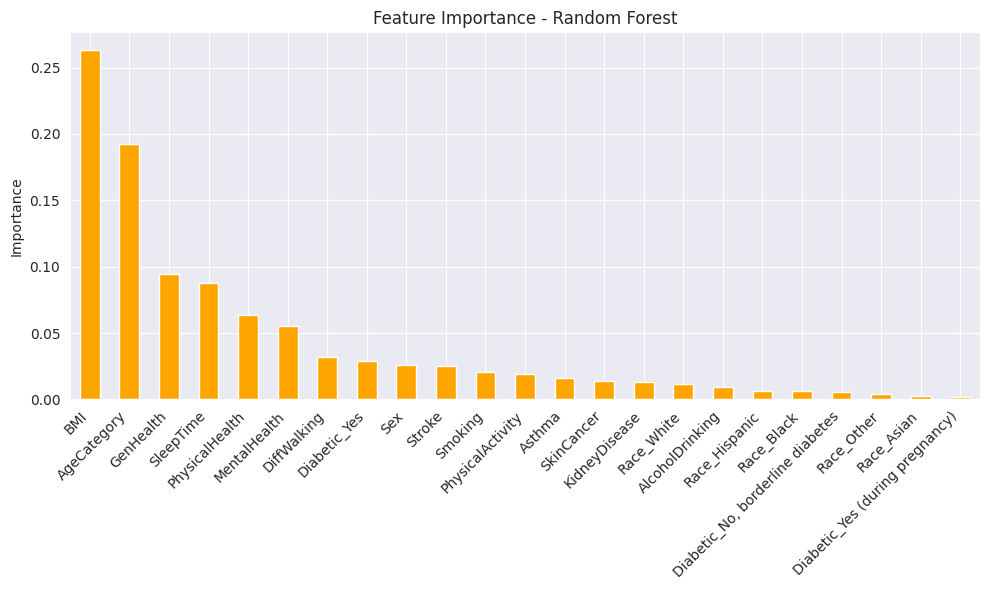

In [50]:
rf_series = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\n=== Random Forest Feature Importances ===")
print(rf_series)
plt.figure(figsize=(10, 6))
rf_series.plot(kind='bar', color='orange')
plt.title('Feature Importance - Random Forest')
plt.ylabel('Importance')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [51]:
top_mi = set(mi_series.head(15).index)
top_rf = set(rf_series.head(15).index)

top_features = list(top_mi.union(top_rf))

print(f"\nSelected {len(top_features)} features:")
print(sorted(top_features))

X_train_df = pd.DataFrame(X_train, columns=X.columns)
X_test_df  = pd.DataFrame(X_test, columns=X.columns)

X_train_sel = X_train_df[top_features]
X_test_sel  = X_test_df[top_features]

# Ensure all columns are numeric (float) to be compatible with XGBoost
X_train_sel = X_train_sel.astype(float)
X_test_sel  = X_test_sel.astype(float)

print(f"\n[FS] X_train after selection: {X_train_sel.shape}")
print(f"[FS] X_test  after selection: {X_test_sel.shape}")


Selected 16 features:
['AgeCategory', 'Asthma', 'BMI', 'Diabetic_Yes', 'DiffWalking', 'GenHealth', 'KidneyDisease', 'MentalHealth', 'PhysicalActivity', 'PhysicalHealth', 'Race_White', 'Sex', 'SkinCancer', 'SleepTime', 'Smoking', 'Stroke']

[FS] X_train after selection: (241373, 16)
[FS] X_test  after selection: (60344, 16)


In [52]:
if HAS_SMOTE:
    print("\nApplying SMOTE to training set...")

    sm = SMOTE(
        random_state=SEED,
        k_neighbors=5
    )

    X_train_bal, y_train_bal = sm.fit_resample(
        X_train_sel,
        y_train
    )

    print(
        f"After SMOTE - Train: {X_train_bal.shape}, "
        f"Positive %: {y_train_bal.mean()*100:.2f}%"
    )

else:
    X_train_bal, y_train_bal = X_train_sel, y_train

    print(
        "SMOTE not available — "
        "using class_weight='balanced' instead."
    )


Applying SMOTE to training set...
After SMOTE - Train: (439128, 16), Positive %: 50.00%


In [53]:
lr = LogisticRegression(
    C=1.0,
    class_weight="balanced",
    max_iter=1000,
    random_state=SEED,
    solver="lbfgs"
)

In [54]:
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=14,
    min_samples_leaf=5,
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=SEED
)

In [55]:
if HAS_XGB:
    scale_pos = (y_train == 0).sum() / (y_train == 1).sum()
    xgb = XGBClassifier(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos,
        use_label_encoder=False,
        eval_metric="auc",
        random_state=SEED,
        n_jobs=-1,
        verbosity=0
    )
else:
    xgb = GradientBoostingClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        random_state=SEED
    )
    print("Using GradientBoosting as XGBoost fallback")

In [56]:
if HAS_LGB:
    lgb = LGBMClassifier(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=8,
        num_leaves=63,
        subsample=0.8,
        colsample_bytree=0.8,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1,
        verbose=-1
    )
else:
    lgb = HistGradientBoostingClassifier(
        max_iter=500,
        learning_rate=0.05,
        max_depth=8,
        min_samples_leaf=25,
        class_weight="balanced",
        random_state=SEED
    )
    print("Using HistGradientBoosting as LightGBM fallback")

In [57]:
hgb = HistGradientBoostingClassifier(
    max_iter=400,
    learning_rate=0.05,
    max_depth=8,
    min_samples_leaf=20,
    l2_regularization=0.2,
    class_weight="balanced",
    random_state=SEED
)
models = {
    "Logistic Regression (Baseline)": lr,
    "Random Forest": rf,
    "XGBoost": xgb,
    "LightGBM": lgb,
    "HistGradientBoosting": hgb
}

In [58]:
individual_results = {}

for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train_bal, y_train_bal)
    probs = model.predict_proba(X_test_sel)[:, 1]
    best_t = 0.5
    best_f1 = 0
    for t in np.arange(0.1, 0.9, 0.01):
        preds_t = (probs >= t).astype(int)
        f1_t = f1_score(y_test, preds_t)
        if f1_t > best_f1:
            best_f1 = f1_t
            best_t = t
    preds = (probs >= best_t).astype(int)
    individual_results[name] = {
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "F1": f1_score(y_test, preds),
        "AUC": roc_auc_score(y_test, probs),
        "Threshold": best_t
    }
    r = individual_results[name]
    print(
        f"Threshold: {best_t:.2f} | "
        f"F1: {r['F1']:.4f} | "
        f"AUC: {r['AUC']:.4f} | "
        f"Recall: {r['Recall']:.4f} | "
        f"Precision: {r['Precision']:.4f} | "
        f"Acc: {r['Accuracy']:.4f}"
    )
print("\n" + "=" * 70)
print("MODEL COMPARISON TABLE")
print("=" * 70)
print(
    f"{'Model':<30}"
    f"{'Acc':>8}"
    f"{'Prec':>8}"
    f"{'Rec':>8}"
    f"{'F1':>8}"
    f"{'AUC':>8}"
)
print("-" * 70)


Training Logistic Regression (Baseline)...
Threshold: 0.71 | F1: 0.3956 | AUC: 0.8309 | Recall: 0.5119 | Precision: 0.3223 | Acc: 0.8587

Training Random Forest...
Threshold: 0.38 | F1: 0.3643 | AUC: 0.8156 | Recall: 0.5816 | Precision: 0.2652 | Acc: 0.8166

Training XGBoost...
Threshold: 0.77 | F1: 0.3752 | AUC: 0.8213 | Recall: 0.5360 | Precision: 0.2886 | Acc: 0.8387

Training LightGBM...
Threshold: 0.26 | F1: 0.3747 | AUC: 0.8221 | Recall: 0.5033 | Precision: 0.2984 | Acc: 0.8482

Training HistGradientBoosting...
Threshold: 0.28 | F1: 0.3739 | AUC: 0.8216 | Recall: 0.5072 | Precision: 0.2961 | Acc: 0.8465

MODEL COMPARISON TABLE
Model                              Acc    Prec     Rec      F1     AUC
----------------------------------------------------------------------


In [59]:
for name, r in individual_results.items():
    print(
        f"{name:<30}"
        f"{r['Accuracy']:>8.4f}"
        f"{r['Precision']:>8.4f}"
        f"{r['Recall']:>8.4f}"
        f"{r['F1']:>8.4f}"
        f"{r['AUC']:>8.4f}"
    )
print("\n" + "=" * 60)
print("STACKING ENSEMBLE")
print("=" * 60)
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)
n_models = len(models)
oof_preds = np.zeros(
    (len(X_train_sel), n_models)
)
test_preds = np.zeros(
    (len(X_test_sel), n_models)
)
for fold, (tr_idx, val_idx) in enumerate(
    skf.split(X_train_sel, y_train)
):
    print(f"Fold {fold+1}/5...")
    Xtr = X_train_sel.iloc[tr_idx]
    Xval = X_train_sel.iloc[val_idx]
    ytr = y_train[tr_idx]
    yval = y_train[val_idx]

    if HAS_SMOTE:
        sm_fold = SMOTE(
            random_state=SEED,
            k_neighbors=5
        )
        Xtr, ytr = sm_fold.fit_resample(
            Xtr,
            ytr
        )
    for i, (name, model) in enumerate(models.items()):

        model.fit(Xtr, ytr)

        oof_preds[val_idx, i] = (
            model.predict_proba(Xval)[:, 1]
        )
        test_preds[:, i] += (
            model.predict_proba(X_test_sel)[:, 1] / 5
        )
test_preds_avg = test_preds

Logistic Regression (Baseline)  0.8587  0.3223  0.5119  0.3956  0.8309
Random Forest                   0.8166  0.2652  0.5816  0.3643  0.8156
XGBoost                         0.8387  0.2886  0.5360  0.3752  0.8213
LightGBM                        0.8482  0.2984  0.5033  0.3747  0.8221
HistGradientBoosting            0.8465  0.2961  0.5072  0.3739  0.8216

STACKING ENSEMBLE
Fold 1/5...
Fold 2/5...
Fold 3/5...
Fold 4/5...
Fold 5/5...


In [60]:
sc = StandardScaler()
meta_train = sc.fit_transform(oof_preds)
meta_test  = sc.transform(test_preds)
meta = LogisticRegression(
    C=2,
    class_weight="balanced",
    max_iter=1000
)
meta.fit(meta_train, y_train)
final_probs = meta.predict_proba(meta_test)[:, 1]

In [61]:
best_t = 0.5
best_f1 = 0
for t in np.arange(0.1, 0.9, 0.01):
    preds_t = (final_probs >= t).astype(int)
    f1 = f1_score(y_test, preds_t)
    if f1 > best_f1:
        best_f1 = f1
        best_t = t
final_preds = (final_probs >= best_t).astype(int)

In [62]:
print("\n" + "=" * 60)
print("FINAL STACKED MODEL RESULTS")
print("=" * 60)

print(f"Best Threshold : {best_t:.2f}")
print(f"F1             : {f1_score(y_test, final_preds):.4f}")
print(f"AUC            : {roc_auc_score(y_test, final_probs):.4f}")
print(f"Recall         : {recall_score(y_test, final_preds):.4f}")
print(f"Precision      : {precision_score(y_test, final_preds):.4f}")
print(f"Accuracy       : {accuracy_score(y_test, final_preds):.4f}")

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, final_preds)
print(cm)
tn, fp, fn, tp = cm.ravel()
print(f"\nTN={tn}")
print(f"FP={fp}")
print(f"FN={fn}")
print(f"TP={tp}")

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        final_preds,
        target_names=[
            "No HeartDisease",
            "HeartDisease"
        ]
    )
)


FINAL STACKED MODEL RESULTS
Best Threshold : 0.72
F1             : 0.3964
AUC            : 0.8330
Recall         : 0.5501
Precision      : 0.3098
Accuracy       : 0.8487

Confusion Matrix:
[[48212  6680]
 [ 2453  2999]]

TN=48212
FP=6680
FN=2453
TP=2999

Classification Report:

                 precision    recall  f1-score   support

No HeartDisease       0.95      0.88      0.91     54892
   HeartDisease       0.31      0.55      0.40      5452

       accuracy                           0.85     60344
      macro avg       0.63      0.71      0.65     60344
   weighted avg       0.89      0.85      0.87     60344



In [63]:
print("\n" + "=" * 60)
print("ERROR ANALYSIS")
print("=" * 60)

cm = confusion_matrix(y_test, final_preds)
tn, fp, fn, tp = cm.ravel()
total = len(y_test)
pos  = y_test.sum()
neg  = total - pos

print(f"Total Test Samples : {total}")
print(f"Actual Positives   : {pos}  ({pos/total*100:.1f}%)")
print(f"Actual Negatives   : {neg}  ({neg/total*100:.1f}%)")
print()
print(f"True Positives (TP) : {tp}  — Correctly identified heart disease")
print(f"True Negatives (TN) : {tn}  — Correctly identified no heart disease")
print(f"False Positives (FP): {fp}  — False alarms (predicted disease, actually healthy)")
print(f"False Negatives (FN): {fn}  — Missed cases (predicted healthy, actually has disease)")
print()
print(f"False Negative Rate (Miss Rate): {fn/pos*100:.2f}%")
print(f"False Positive Rate           : {fp/neg*100:.2f}%")
print()
print("Key Insight:")
print(f"  The model misses {fn/pos*100:.1f}% of actual heart disease cases (FN).")
print(f"  In medical settings, reducing FN is critical — we want high Recall.")
print(f"  A lower threshold increases Recall but decreases Precision (trade-off).")

print("\n" + "=" * 60)
print("DONE — All results above are from the HELD-OUT TEST SET.")
print("Random seed = 42 | Results are fully reproducible.")
print("=" * 60)


ERROR ANALYSIS
Total Test Samples : 60344
Actual Positives   : 5452  (9.0%)
Actual Negatives   : 54892  (91.0%)

True Positives (TP) : 2999  — Correctly identified heart disease
True Negatives (TN) : 48212  — Correctly identified no heart disease
False Positives (FP): 6680  — False alarms (predicted disease, actually healthy)
False Negatives (FN): 2453  — Missed cases (predicted healthy, actually has disease)

False Negative Rate (Miss Rate): 44.99%
False Positive Rate           : 12.17%

Key Insight:
  The model misses 45.0% of actual heart disease cases (FN).
  In medical settings, reducing FN is critical — we want high Recall.
  A lower threshold increases Recall but decreases Precision (trade-off).

DONE — All results above are from the HELD-OUT TEST SET.
Random seed = 42 | Results are fully reproducible.
